# EDA e feature engineering do Occasion Score

Análise exploratória da tabela de modelagem (POF 2008-09 e 2017-18, IBGE) e o porquê de
cada feature do modelo final.

- **Unidade:** pessoa × dia de registro × turno. Cada pessoa-dia gera os quatro turnos,
  comendo ou não neles.
- **Target (`alvo_pizza_refri`):** pizza e refrigerante (genérico ou marca) com até 1 hora
  de diferença no turno.
- **Pesos:** `peso_final` (expansão da POF) × `fator_dia` (cada dia da semana vale 1/7). As
  taxas abaixo são ponderadas, salvo quando a tabela diz "n" (contagem bruta).

Para reproduzir (os microdados não ficam no git, cerca de 2,3 GB):

```bash
uv run python -m occasion.ingestao.download   # baixa a POF do FTP do IBGE
uv run python -m occasion.ingestao.pof         # consumo harmonizado
uv run python -m occasion.modelagem.tabela     # tabela de modelagem
uv run --group eda jupytext --to ipynb --execute notebooks/eda_occasion_score.py
```

Este notebook é gerado a partir de `notebooks/eda_occasion_score.py` (jupytext); edite o
`.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from occasion.modelagem.tabela import caminho_tabela

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
VERMELHO, AZUL, CINZA = "#c8102e", "#4e79a7", "#9a9a9a"
CORES_EDICAO = {"2008-09": CINZA, "2017-18": VERMELHO}

tabelas = {e: pd.read_parquet(caminho_tabela(e)) for e in ("2008_2009", "2017_2018")}
df = pd.concat(tabelas.values(), ignore_index=True)
df["w"] = df["peso_final"] * df["fator_dia"].astype(float)
df["y"] = df["alvo_pizza_refri"].astype(int)
DIAS = {1: "seg", 2: "ter", 3: "qua", 4: "qui", 5: "sex", 6: "sáb", 7: "dom"}


def taxa(d: pd.DataFrame, por: list[str] | str, col: str = "y") -> pd.DataFrame:
    """Taxa ponderada (%) e número de positivos por grupo e edição."""
    por = [por] if isinstance(por, str) else por
    g = d.groupby(["edicao", *por], observed=True)
    out = pd.DataFrame(
        {
            "taxa_pct": 100 * g.apply(lambda x: np.average(x[col], weights=x["w"])),
            "positivos": g[col].sum(),
        }
    )
    return out

## 1. A base

Duas edições da POF, com o mesmo processamento. A de 2008-09 treina a validação temporal e
a de 2017-18 testa.

In [2]:
resumo = df.groupby("edicao").agg(
    pessoas=("id_pessoa", "nunique"),
    domicilios=("id_domicilio", "nunique"),
    setores=("id_setor", "nunique"),
    linhas=("y", "size"),
    positivos=("y", "sum"),
)
resumo["pessoa_dias"] = resumo["linhas"] // 4
resumo["taxa_pct"] = df.groupby("edicao").apply(lambda x: 100 * np.average(x["y"], weights=x["w"]))
resumo

,pessoas,domicilios,setores,linhas,positivos,pessoa_dias,taxa_pct
edicao,,,,,,,
2008-09,34003,13569,4328,267612,668,66903,0.392
2017-18,46164,20112,5404,340072,811,85018,0.327


A ocasião é rara: 0,39% dos turnos em 2008-09 e 0,33% em 2017-18. Por isso a métrica principal do modelo é a
PR-AUC (o ROC-AUC fica alto mesmo para um modelo fraco quando os negativos são 99,7%).

### Quanto da pizza vem com refrigerante

O target só faz sentido se pizza e refrigerante andam juntos. Entre os turnos com pizza,
a fração com refrigerante no mesmo turno (até 1 hora). A queda entre as edições é parte do
que o modelo precisa absorver: a ocasião pizza + refrigerante ficou menos frequente dentro
da própria pizza.

In [3]:
com_pizza = df[df["teve_pizza"]]
pd.DataFrame(
    {
        "turnos_com_pizza": com_pizza.groupby("edicao").size(),
        "pct_com_refri": com_pizza.groupby("edicao").apply(
            lambda x: 100 * np.average(x["y"], weights=x["w"])
        ),
    }
)

,turnos_com_pizza,pct_com_refri
edicao,,
2008-09,1166,62.495
2017-18,1697,44.138


## 2. Momento: turno e dia da semana

O brief diz que a ocasião "se concentra de sexta a domingo, à noite e dentro de casa". A
POF confirma a noite com folga e mostra que o dia importa, mas bem menos que o turno.

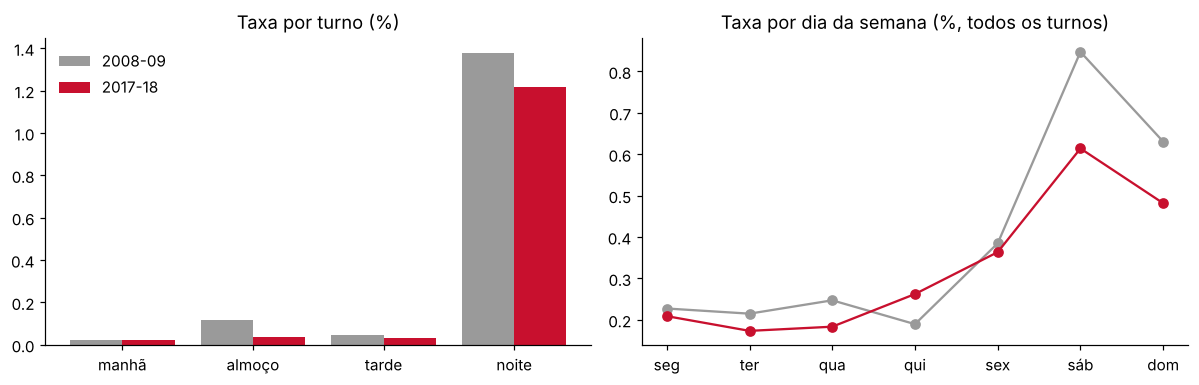

In [4]:
t_turno = taxa(df, "turno").reset_index()
t_dia = taxa(df, "dia_semana").reset_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for ed, cor in CORES_EDICAO.items():
    a = t_turno[t_turno["edicao"] == ed]
    ax[0].bar(
        np.arange(4) + (0.2 if ed == "2017-18" else -0.2), a["taxa_pct"], 0.4, color=cor, label=ed
    )
    b = t_dia[t_dia["edicao"] == ed]
    ax[1].plot(b["dia_semana"].astype(int).map(DIAS), b["taxa_pct"], "o-", color=cor, label=ed)
ax[0].set_xticks(range(4), ["manhã", "almoço", "tarde", "noite"])
ax[0].set_title("Taxa por turno (%)")
ax[1].set_title("Taxa por dia da semana (%, todos os turnos)")
ax[0].legend(frameon=False)
plt.tight_layout()

In [5]:
noite = df[df["turno"] == "noite"]
share_noite = df.groupby("edicao").apply(
    lambda x: 100 * (x["y"] * x["w"])[x["turno"] == "noite"].sum() / (x["y"] * x["w"]).sum()
)
print("Ocasiões que caem à noite (%):", share_noite.round(1).to_dict())

Ocasiões que caem à noite (%): {'2008-09': 88.1, '2017-18': 93.3}


### Dia × turno: o que o baseline já sabe

O baseline obrigatório do brief é a frequência histórica por dia da semana e turno. O mapa
abaixo é esse baseline, estimado em 2008-09 e visto em 2017-18. O modelo precisa ganhar dele
com público e lugar.

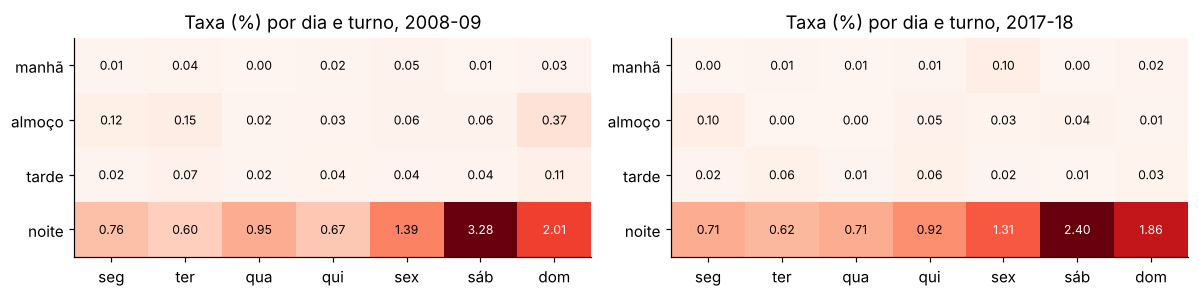

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
for i, ed in enumerate(CORES_EDICAO):
    m = taxa(df[df["edicao"] == ed], ["turno", "dia_semana"])["taxa_pct"].unstack()
    m.index = m.index.droplevel(0)
    m.columns = [DIAS[int(c)] for c in m.columns]
    im = ax[i].imshow(m.values, cmap="Reds", aspect="auto")
    ax[i].set_xticks(range(7), m.columns)
    ax[i].set_yticks(range(4), ["manhã", "almoço", "tarde", "noite"])
    for (r, c), v in np.ndenumerate(m.values):
        ax[i].text(
            c,
            r,
            f"{v:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if v > m.values.max() / 2 else "black",
        )
    ax[i].set_title(f"Taxa (%) por dia e turno, {ed}")
plt.tight_layout()

## 3. Lugar: região e tipo de área

`tipo_area` vem dos estratos da amostra da POF (capital, resto da região metropolitana,
interior urbano e rural; tabelas de estratos do IBGE, em `data/referencia/estratos_pof.csv`).
Ela substituiu a variável urbano/rural (`situacao`) porque separa a capital do resto: a taxa
da capital é 2,1 vezes a do interior urbano em 2008-09 e 1,6 vez em 2017-18.

In [7]:
pd.concat(
    {
        "região": taxa(df, "regiao")["taxa_pct"].unstack(0),
        "tipo de área": taxa(df, "tipo_area")["taxa_pct"].unstack(0),
    }
)

edicao                        2008-09  2017-18
região       Centro-Oeste       0.645    0.372
             Nordeste           0.155    0.250
             Norte              0.199    0.213
             Sudeste            0.456    0.343
             Sul                0.584    0.467
tipo de área capital            0.711    0.476
             resto_rm           0.372    0.446
             interior_urbano    0.341    0.292
             rural              0.086    0.059

## 4. Público: idade, sexo e renda

A renda entra no modelo como percentil dentro da edição (`renda_pct`), e não em salários
mínimos: o salário mínimo subiu cerca de 35% em termos reais entre janeiro de 2009 e janeiro
de 2018 (IPCA, série do IBGE), então o mesmo valor em SM não é o mesmo lugar na distribuição.
As classes por SM (corte usual do IBGE) aparecem só nos relatórios e no Decision Engine.

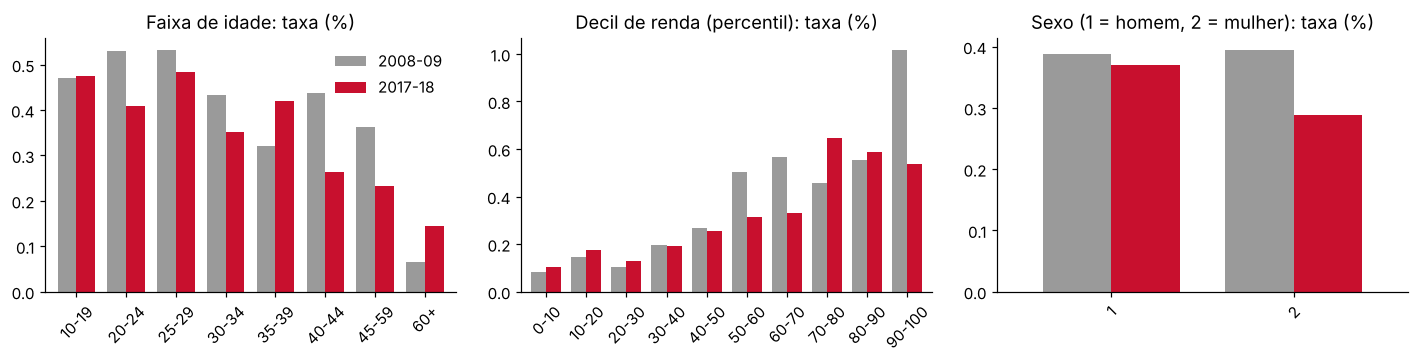

In [8]:
df["decil_renda"] = pd.cut(
    df["renda_pct"],
    np.arange(0, 101, 10),
    include_lowest=True,
    labels=[f"{i}-{i + 10}" for i in range(0, 100, 10)],
)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for col, a, titulo in [
    ("faixa_idade", ax[0], "Faixa de idade"),
    ("decil_renda", ax[1], "Decil de renda (percentil)"),
    ("sexo", ax[2], "Sexo (1 = homem, 2 = mulher)"),
]:
    t = taxa(df, col)["taxa_pct"].unstack(0)
    t.plot(kind="bar", ax=a, color=[CORES_EDICAO[c] for c in t.columns], width=0.75, legend=False)
    a.set_title(f"{titulo}: taxa (%)")
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=45)
ax[0].legend(frameon=False)
plt.tight_layout()

In [9]:
df["classe"] = pd.cut(df["renda_sm"], [-np.inf, 2, 4, 10, 20, np.inf], labels=list("EDCBA"))
rec = df[df["edicao"] == "2017-18"]
cls = taxa(rec, "classe").droplevel(0)
cls["pct_das_ocasioes"] = (
    100
    * rec.groupby("classe", observed=True).apply(lambda x: (x["y"] * x["w"]).sum())
    / (rec["y"] * rec["w"]).sum()
)
cls.loc[list("ABCDE")]

,taxa_pct,positivos,pct_das_ocasioes
classe,,,
A,0.439,26,4.886
B,0.675,112,18.556
C,0.454,375,47.881
D,0.204,199,19.909
E,0.136,99,8.768


Em 2017-18 a maior taxa é a da classe B, e a classe A fica perto da C. O brief cita maior
consumo de pizza na classe A com dados da Ambev, que não temos para comparar; aqui a classe é
pela renda do domicílio em salários mínimos, e a classe A tem só 26 ocasiões na amostra. O
ponto firme é outro: as classes B a D somam 86% das ocasiões, porque são a maior parte da
população. É isso que sustenta a regra 4 do Decision Engine (awareness nas classes B a D).

## 5. Canal: em casa ou fora

A POF registra se o alimento foi consumido dentro ou fora do domicílio, mas não tem código de
delivery (questionário POF 7 do IBGE): pizza entregue conta como "em casa". Por isso o canal
não é feature do modelo; entra como entrada opcional do app e muda só o canal da regra 2.

In [10]:
pos = df[df["y"] == 1]
pos.groupby("edicao").apply(
    lambda x: pd.Series(
        {
            "pct_em_casa": 100 * np.average(~x["fora_de_casa"].fillna(False), weights=x["w"]),
            "n": len(x),
        }
    )
)

,pct_em_casa,n
edicao,,
2008-09,64.702,668.0
2017-18,69.155,811.0


## 6. Guaraná dentro da ocasião

Fatia das ocasiões de pizza com refrigerante em que o refrigerante inclui guaraná. É o espaço
de conversão da regra 2: a ocasião acontece, mas o guaraná está em uma minoria delas. O
intervalo de confiança por bootstrap de setores está no relatório de avaliação
(`docs/relatorios/avaliacao_occasion_score.md`).

In [11]:
taxa(pos.assign(g=pos["teve_guarana"].astype(int)), "regiao", col="g").rename(
    columns={"taxa_pct": "pct_com_guarana", "positivos": "com_guarana"}
)

pct_com_guarana  com_guarana
edicao  regiao                                    
2008-09 Centro-Oeste            8.439           17
        Nordeste               34.478           32
        Norte                  17.150            8
        Sudeste                 7.946           22
        Sul                    19.642           24
2017-18 Centro-Oeste           20.690           25
        Nordeste               21.374           70
        Norte                  24.002           20
        Sudeste                21.454           42
        Sul                    19.040           28

## 7. O que muda entre as edições

Taxa por segmento em 2017-18 dividida pela de 2008-09. Um modelo que só funcionasse com o
padrão de 2008-09 erraria onde essa razão se afasta de 1, e é por isso que a validação é
temporal (treino 2008-09, teste 2017-18) e não um sorteio aleatório.

In [12]:
mud = []
for col in ["turno", "regiao", "tipo_area", "faixa_idade"]:
    t = taxa(df, col)["taxa_pct"].unstack(0)
    t["razao_2017_sobre_2008"] = t["2017-18"] / t["2008-09"]
    t.index = [f"{col} = {v}" for v in t.index]
    mud.append(t)
pd.concat(mud).sort_values("razao_2017_sobre_2008")

edicao,2008-09,2017-18,razao_2017_sobre_2008
turno = almoco,0.116,0.035,0.303
regiao = Centro-Oeste,0.645,0.372,0.577
faixa_idade = 40-44,0.437,0.263,0.602
faixa_idade = 45-59,0.362,0.233,0.645
turno = tarde,0.047,0.031,0.659
tipo_area = capital,0.711,0.476,0.669
tipo_area = rural,0.086,0.059,0.686
regiao = Sudeste,0.456,0.343,0.752
faixa_idade = 20-24,0.530,0.409,0.771
regiao = Sul,0.584,0.467,0.800


## 8. Feature engineering: o que entrou, o que saiu e por quê

| feature | como entra | por quê |
|---|---|---|
| `turno` | categoria (manhã até 10h, almoço até 14h, tarde até 17h, noite) | a noite tem 88% (2008-09) e 93% (2017-18) das ocasiões |
| `dia_semana` | categoria (1 a 7), não número | o efeito não é linear (sábado > domingo > sexta); agrupar seg-qui não mudou a PR-AUC |
| `regiao` | categoria | captura a diferença regional; o Google Trends por UF empatou com ela no ranking e saiu do modelo |
| `tipo_area` | categoria, dos estratos da POF | capital com 2,1× (2008-09) e 1,6× (2017-18) a taxa do interior urbano; separa o que urbano/rural mistura |
| `faixa_idade` | categoria (10-19 ... 60+) | relação não monotônica com a idade |
| `sexo` | categoria | pouco efeito, mantido pela análise por público |
| `renda_pct` | percentil ponderado dentro da edição, com splines | comparável entre edições; efeito não linear |

**Testadas e removidas por ablação** (relatório `docs/relatorios/experimentos_occasion_score.md`):
`tem_crianca` e `n_moradores` (diferença de PR-AUC com IC95 cruzando zero; `tem_crianca`
troca de sinal entre edições), posição do Google Trends por UF (empate com região; fica para
o Trend Radar), `fim_de_semana` e `quarta` (redundantes com `dia_semana`).

**Fora do modelo para não vazar informação:** o instante de previsão é antes do turno, com
perfil, lugar e calendário. Ficam fora local da refeição, tipo de refeição, dia atípico
(declarado depois, só em 2017-18), dieta e qualquer item consumido. `teve_pizza`,
`teve_guarana` e `fora_de_casa` existem na tabela só para análise.

**Sem data:** a POF registra o dia da semana e a hora, mas não a data do consumo. Clima e
feriados não podem entrar no modelo; ficam para o Trend Radar.

## 9. Conclusões da EDA

1. A ocasião é rara (0,33% dos turnos em 2017-18) e noturna (93%); a métrica principal tem de ser de
   ranking em base desbalanceada (PR-AUC), com o baseline dia × turno como régua.
2. Público e lugar mudam a taxa várias vezes (renda, idade, capital), o que dá espaço para o
   modelo ganhar do baseline.
3. As classes B a D têm 86% das ocasiões; a classe A, 5%.
4. O guaraná aparece em uma minoria das ocasiões em todas as regiões: há ocasião para
   converter, não só para criar.
5. As taxas mudam entre 2008-09 e 2017-18, o que justifica a validação temporal.